**CS 4140 – Deep Learning · L16 · Sequences II: memory and learning over time** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OWNER/4140-deep-learning/blob/main/lectures/L16_sequences-2/L16_memory_lstm.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L16_sequences-2"
REPO = "https://github.com/OWNER/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 16 · Sequences II: memory and learning over time
**Mon 1 Mar 2027 · demo notebook**

How far back can a recurrent network remember? A controlled memory test, the gradients behind the answer, an LSTM unit built by hand, and Friday's forecast again.

**Before class:** run all cells once (about 40 seconds on a laptop CPU with the default settings). Everything slow is saved in `saved/`:

* `LIVE_RACE = True` trains an RNN and an LSTM side by side for about 10 seconds each (section 2). Set it to `False` to skip.
* `RUN_GRID = False` loads the saved grid of 54 training runs (section 3). `True` recomputes it: about 30 minutes on one CPU core.
* `TRAIN_FORECAST = False` loads the saved Charlottetown LSTM and GRU (section 8). `True` retrains them: about a minute.

| Section | What it shows |
|---|---|
| 1 | The memory test |
| 2 | A live race: RNN against LSTM |
| 3 | Saved runs: how far back each network remembers |
| 4 | Why: gradients through time |
| 5 | Exploding gradients and clipping |
| 6 | Inside an LSTM: a unit built by hand, and what training found |
| 7 | The GRU |
| 8 | Back to Charlottetown |
| 9 | Exercises |

Requires `torch`, `numpy`, `pandas`, `matplotlib`. Section 8 reads `data/charlottetown_daily_2013_2025.csv` and `saved/l15_rnn.pt` from Friday's notebook.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

LIVE_RACE = True        # section 2: ~10 s per network
RUN_GRID = False        # section 3: True recomputes 54 runs (~30 min); False loads saved/l16_grid.json
TRAIN_FORECAST = False  # section 8: True retrains the Charlottetown LSTM and GRU (~1 min)

DATA, SAVED, FIGS = Path("data"), Path("saved"), Path("figures")
SAVED.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

# Colours used on the slides: LSTM blue, RNN orange, GRU green, text black, reference lines grey
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
COLOURS = {"lstm": "#2a78d6", "rnn": "#eb6834", "gru": "#1baf7a"}
NAMES = {"rnn": "RNN", "lstm": "LSTM", "gru": "GRU"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False,
})
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


## 1. The memory test

Each sequence has `L` steps and two input channels:

* **value:** random noise from N(0, 1), except at one random step, where it holds the **signal**, +1 or −1;
* **marker:** 1 at the signal step, 0 everywhere else.

After the last step the network must say whether the signal was +1 or −1. The noise is as large as the signal, so a network must *write* at the marker, *ignore* everything else, and *keep* the bit until the end. Chance is 50%, and a loss stuck at ln 2 ≈ 0.693 means the network has not found the signal.

The training setup is the same for every network: 32 hidden units, Adam (learning rate 0.003), minibatches of 64 fresh sequences, gradient clipping at norm 1, 3,000 steps.

In [2]:
NOISE_SD = 1.0      # distractor noise, same size as the signal
HIDDEN = 32         # units in every network
STEPS = 3000        # training steps (minibatches of 64)
LR = 3e-3           # Adam learning rate
CLIP = 1.0          # gradient clipping (max norm)


def memory_batch(batch_size, seq_len, gen, pos=None, signal=None, noise_sd=NOISE_SD):
    """The memory test.

    Each sequence has seq_len steps with two input channels:
      channel 0: noise ~ N(0, noise_sd^2), except one step that holds the signal (+1 or -1)
      channel 1: a marker, 1 at the signal step and 0 elsewhere
    The target is 1 if the signal was +1, else 0. It is read after the last step.
    Returns x (batch, seq_len, 2), y (batch,), delay (steps from the signal to the end).
    """
    if signal is None:
        signal = torch.randint(0, 2, (batch_size,), generator=gen).float() * 2 - 1
    if pos is None:
        pos = torch.randint(0, seq_len, (batch_size,), generator=gen)
    value = torch.randn(batch_size, seq_len, generator=gen) * noise_sd
    marker = torch.zeros(batch_size, seq_len)
    rows = torch.arange(batch_size)
    value[rows, pos] = signal
    marker[rows, pos] = 1.0
    x = torch.stack([value, marker], dim=-1)
    y = (signal > 0).float()
    return x, y, seq_len - pos


class MemoryNet(nn.Module):
    """A recurrent layer (RNN, LSTM or GRU) followed by a linear read-out of the last state."""

    def __init__(self, cell="rnn", hidden=HIDDEN):
        super().__init__()
        layer = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.cell = cell
        self.rnn = layer(input_size=2, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)                    # out: (batch, time, hidden)
        return self.head(out[:, -1]).squeeze(-1)  # one logit per sequence


def train_memory(cell, seq_len, seed, steps=STEPS, log_every=0, noise_sd=NOISE_SD):
    """Train one network on the memory test. Returns the model and its loss history."""
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(1000 + seed)
    model = MemoryNet(cell)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []
    t0 = time.time()
    for step in range(1, steps + 1):
        x, y, _ = memory_batch(64, seq_len, gen, noise_sd=noise_sd)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        opt.step()
        history.append(loss.item())
        if log_every and step % log_every == 0:
            print(f"  {cell:4s} L={seq_len:3d} step {step:5d}  loss {np.mean(history[-log_every:]):.3f}  ({time.time() - t0:.0f} s)")
    return model, history


@torch.no_grad()
def evaluate_memory(model, seq_len, n=5000, seed=999, noise_sd=NOISE_SD):
    x, y, delay = memory_batch(n, seq_len, torch.Generator().manual_seed(seed), noise_sd=noise_sd)
    correct = ((model(x) > 0).float() == y).float()
    return correct.mean().item(), correct, delay


def solved_at(history, window=50, threshold=0.1):
    """First training step where the running loss drops below the threshold (None if never)."""
    h = np.asarray(history)
    run = np.convolve(h, np.ones(window) / window, mode="valid")
    idx = np.where(run < threshold)[0]
    return int(idx[0] + window) if len(idx) else None

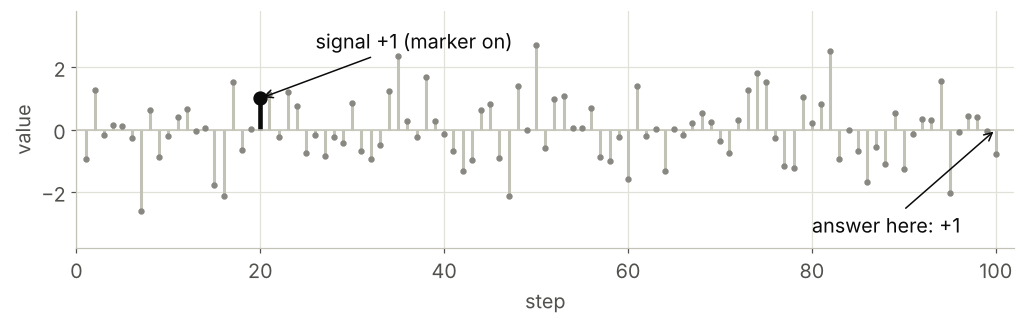

target: 1 (1 means +1) · steps from the signal to the end: 81


In [3]:
# One example: the signal (+1) sits at step 20 of 100
x_example, y_example, delay = memory_batch(1, 100, torch.Generator().manual_seed(4), pos=torch.tensor([19]),
                                           signal=torch.tensor([1.0]))
value = x_example[0, :, 0].numpy()
steps = np.arange(1, 101)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.vlines(steps, 0, value, color="#c3c2b7", lw=2)
ax.scatter(steps, value, s=10, color=MUTED, zorder=3)
ax.vlines(20, 0, value[19], color=INK, lw=3)
ax.scatter([20], [value[19]], s=70, color=INK, zorder=4)
ax.annotate("signal +1 (marker on)", (20, value[19]), xytext=(26, 2.6), color=INK,
            arrowprops=dict(arrowstyle="->", color=INK))
ax.annotate("answer here: +1", (100, 0), xytext=(80, -3.3), color=INK,
            arrowprops=dict(arrowstyle="->", color=INK))
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xlim(0, 102)
ax.set_ylim(-3.8, 3.8)
ax.set_xlabel("step")
ax.set_ylabel("value")
fig.savefig(FIGS / "l16_task.png")
plt.show()
print("target:", int(y_example.item()), "(1 means +1) · steps from the signal to the end:", int(delay.item()))

## 2. A live race: RNN against LSTM

Same data, same 32 units, same optimizer; 1,500 steps on 100-step sequences. Watch the loss: 0.693 is guessing.

In [4]:
if LIVE_RACE:
    race = {}
    for cell in ["rnn", "lstm"]:
        t0 = time.time()
        model, hist = train_memory(cell, 100, seed=0, steps=1500, log_every=250)
        acc, _, _ = evaluate_memory(model, 100)
        race[cell] = acc
        print(f"{NAMES[cell]}: accuracy {acc:.1%} after 1,500 steps ({time.time() - t0:.0f} s)\n")

  rnn  L=100 step   250  loss 0.694  (2 s)


  rnn  L=100 step   500  loss 0.693  (3 s)


  rnn  L=100 step   750  loss 0.693  (5 s)


  rnn  L=100 step  1000  loss 0.693  (7 s)


  rnn  L=100 step  1250  loss 0.693  (8 s)


...

  lstm L=100 step   500  loss 0.694  (4 s)


  lstm L=100 step   750  loss 0.693  (5 s)


  lstm L=100 step  1000  loss 0.328  (7 s)


  lstm L=100 step  1250  loss 0.005  (9 s)


  lstm L=100 step  1500  loss 0.006  (10 s)
LSTM: accuracy 100.0% after 1,500 steps (10 s)



## 3. Saved runs: how far back can each network remember?

Every network at six sequence lengths, three seeds each: 54 runs of 3,000 steps. Accuracy is measured on 5,000 fresh sequences.

In [5]:
if RUN_GRID:
    grid = []
    for L in [10, 20, 30, 50, 100, 200]:
        for cell in ["rnn", "lstm", "gru"]:
            for seed in [0, 1, 2]:
                t0 = time.time()
                model, hist = train_memory(cell, L, seed)
                acc, _, _ = evaluate_memory(model, L)
                grid.append({"cell": cell, "L": L, "seed": seed, "accuracy": acc,
                             "solved_at": solved_at(hist), "seconds": round(time.time() - t0, 1),
                             "loss_every_50": [round(sum(hist[i:i + 50]) / 50, 4) for i in range(0, len(hist), 50)]})
                print(f"{cell:4s} L={L:3d} seed {seed}: accuracy {acc:.3f}")
                if L == 100 and seed == 0:
                    torch.save(model.state_dict(), SAVED / f"l16_{cell}_L100_seed0.pt")
    json.dump(grid, open(SAVED / "l16_grid.json", "w"))
else:
    grid = json.load(open(SAVED / "l16_grid.json"))

table = pd.DataFrame(grid).pivot_table(index="L", columns="cell", values="accuracy", aggfunc=list)
print("accuracy per seed (rows: sequence length L)")
for L, row in table.iterrows():
    print(f"L={L:3d}  " + "   ".join(f"{NAMES[c]:4s} {' '.join(f'{a:.0%}' for a in row[c])}" for c in ["rnn", "lstm", "gru"]))

accuracy per seed (rows: sequence length L)
L= 10  RNN  100% 100% 100%   LSTM 100% 100% 100%   GRU  100% 100% 100%
L= 20  RNN  100% 65% 100%   LSTM 100% 100% 100%   GRU  100% 100% 100%
L= 30  RNN  52% 53% 49%   LSTM 100% 100% 100%   GRU  100% 100% 100%
L= 50  RNN  51% 50% 51%   LSTM 100% 100% 100%   GRU  100% 100% 100%
L=100  RNN  49% 51% 51%   LSTM 100% 100% 100%   GRU  100% 100% 100%
L=200  RNN  49% 51% 49%   LSTM 100% 100% 100%   GRU  100% 100% 100%


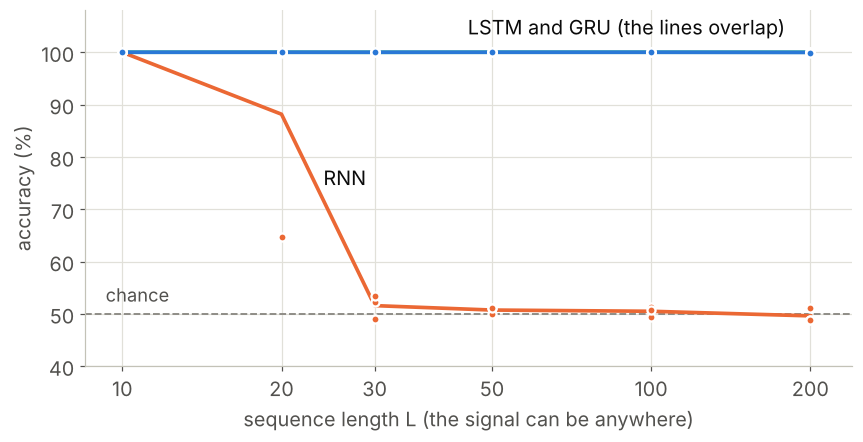

In [6]:
# Slide figure: accuracy against sequence length
lengths = sorted({r["L"] for r in grid})
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhline(50, color=MUTED, lw=1.2, ls="--")
ax.text(9.3, 51.5, "chance", va="bottom", color="#52514e", fontsize=12)
for cell in ["rnn", "gru", "lstm"]:
    accs = np.array([[r["accuracy"] * 100 for r in grid if r["cell"] == cell and r["L"] == L] for L in lengths])
    ax.plot(lengths, accs.mean(1), "-", color=COLOURS[cell], lw=2.4, zorder=3)
    for j, L in enumerate(lengths):
        ax.scatter([L] * accs.shape[1], accs[j], s=28, color=COLOURS[cell], zorder=4,
                   edgecolor="white", linewidth=1.5)
ax.text(45, 102.5, "LSTM and GRU (the lines overlap)", va="bottom", color=INK, fontsize=13)
ax.text(24, 76, "RNN", va="center", color=INK, fontsize=13)
ax.set_xscale("log")
ax.set_xticks(lengths)
ax.set_xticklabels([str(L) for L in lengths])
ax.minorticks_off()
ax.set_xlim(8.5, 240)
ax.set_ylim(40, 108)
ax.set_xlabel("sequence length L (the signal can be anywhere)")
ax.set_ylabel("accuracy (%)")
fig.savefig(FIGS / "l16_accuracy_vs_length.png")
plt.show()

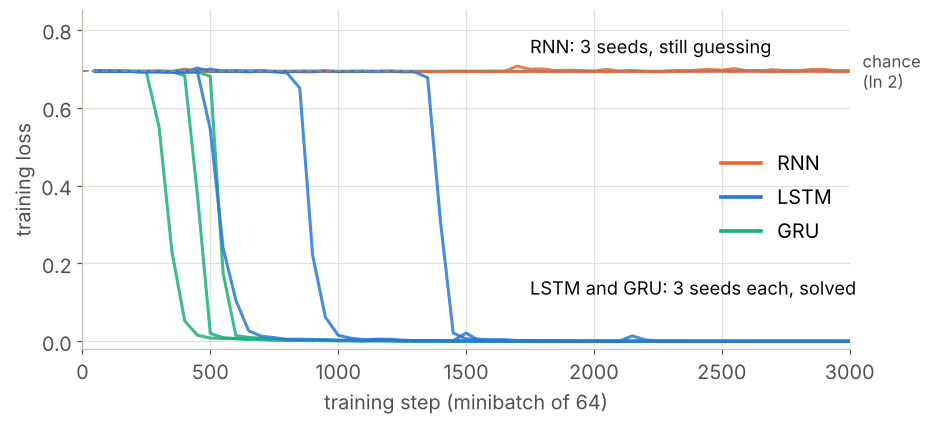

RNN  on 100 steps: loss below 0.1 after [None, None, None] steps
LSTM on 100 steps: loss below 0.1 after [918, 1422, 568] steps
GRU  on 100 steps: loss below 0.1 after [557, 475, 385] steps


In [7]:
# Slide figure: training curves on 100-step sequences (three seeds each)
fig, ax = plt.subplots(figsize=(9, 4.0))
steps_axis = np.arange(50, 3001, 50)
for cell in ["rnn", "gru", "lstm"]:
    for r in [r for r in grid if r["cell"] == cell and r["L"] == 100]:
        ax.plot(steps_axis, r["loss_every_50"], color=COLOURS[cell], lw=2, alpha=0.85)
ax.axhline(np.log(2), color=MUTED, lw=1.2, ls="--")
ax.text(3050, np.log(2), "chance\n(ln 2)", va="center", color="#52514e", fontsize=11)
ax.text(1750, 0.74, "RNN: 3 seeds, still guessing", color=INK, fontsize=12)
ax.text(1750, 0.12, "LSTM and GRU: 3 seeds each, solved", color=INK, fontsize=12)
ax.set_xlim(0, 3000)
ax.set_ylim(-0.02, 0.85)
ax.set_xlabel("training step (minibatch of 64)")
ax.set_ylabel("training loss")
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], color=COLOURS[c], lw=2.4) for c in ["rnn", "lstm", "gru"]],
          [NAMES[c] for c in ["rnn", "lstm", "gru"]], loc="center right", bbox_to_anchor=(1.0, 0.45))
fig.savefig(FIGS / "l16_training_curves.png")
plt.show()

for cell in ["rnn", "lstm", "gru"]:
    sa = [r["solved_at"] for r in grid if r["cell"] == cell and r["L"] == 100]
    print(f"{NAMES[cell]:4s} on 100 steps: loss below 0.1 after {sa} steps")

## 4. Why: gradients through time

Unrolled over $T$ steps, a recurrent network is a $T$-layer network with **one set of weights**. Backpropagation through time is the chain rule along that graph:

$$\frac{\partial h_T}{\partial h_1} = \frac{\partial h_T}{\partial h_{T-1}}\,\frac{\partial h_{T-1}}{\partial h_{T-2}}\cdots\frac{\partial h_2}{\partial h_1}$$

For one unit, each factor is $w_h\,\tanh'(z_t)$, at most $|w_h|$ in size. A product of many such factors shrinks or grows exponentially.

w = 0.5:  w^20 = 9.54e-07   w^50 = 8.88e-16   w^100 = 7.89e-31
w = 0.9:  w^20 = 1.22e-01   w^50 = 5.15e-03   w^100 = 2.66e-05
w = 1.0:  w^20 = 1.00e+00   w^50 = 1.00e+00   w^100 = 1.00e+00
w = 1.1:  w^20 = 6.73e+00   w^50 = 1.17e+02   w^100 = 1.38e+04


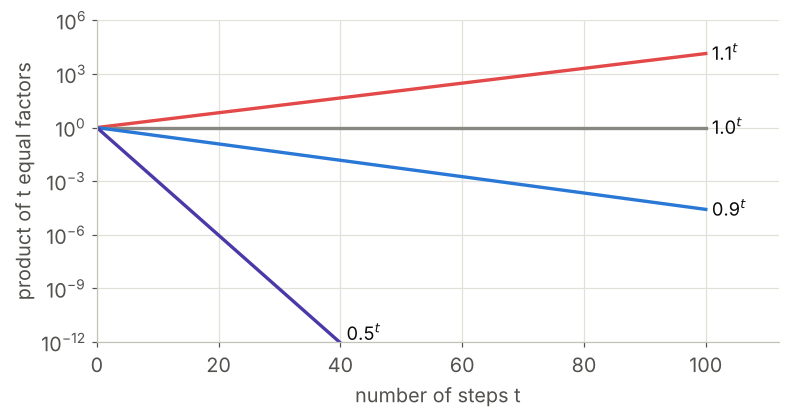

In [8]:
for w in [0.5, 0.9, 1.0, 1.1]:
    print(f"w = {w}:  w^20 = {w**20:.2e}   w^50 = {w**50:.2e}   w^100 = {w**100:.2e}")

fig, ax = plt.subplots(figsize=(8, 3.8))
t = np.arange(0, 101)
for w, colour in [(1.1, "#e34948"), (1.0, MUTED), (0.9, "#2a78d6"), (0.5, "#4a3aa7")]:
    ax.plot(t, w ** t, color=colour, lw=2.2)
for w, xy in [(1.1, (101, 1.1 ** 100)), (1.0, (101, 1.0)), (0.9, (101, 0.9 ** 100)), (0.5, (41, 3e-12))]:
    ax.text(*xy, f"{w}$^t$", va="center", color=INK, fontsize=12)
ax.set_yscale("log")
ax.set_ylim(1e-12, 1e6)
ax.set_xlim(0, 112)
ax.set_xlabel("number of steps t")
ax.set_ylabel("product of t equal factors")
fig.savefig(FIGS / "l16_products.png")
plt.show()

**How much of the answer depends on each step?** We nudge the input at every step and measure how much the network's output responds: $\lVert \partial \hat{y} / \partial x_t \rVert$, averaged over 256 sequences with the signal at step 1. This is exactly the signal that gradient descent needs to learn to use step 1.

init     RNN   step 1: 1.3e-21   step 50: 7.8e-12   step 100: 6.3e-02
init     LSTM  step 1: 1.3e-23   step 50: 9.6e-14   step 100: 1.9e-02
init     GRU   step 1: 8.6e-23   step 50: 8.2e-13   step 100: 4.2e-02
trained  RNN   step 1: 2.2e-22   step 50: 9.5e-15   step 100: 1.3e-03
trained  LSTM  step 1: 2.8e-01   step 50: 3.0e-02   step 100: 4.9e-01
trained  GRU   step 1: 7.5e+00   step 50: 3.4e-03   step 100: 1.5e+00


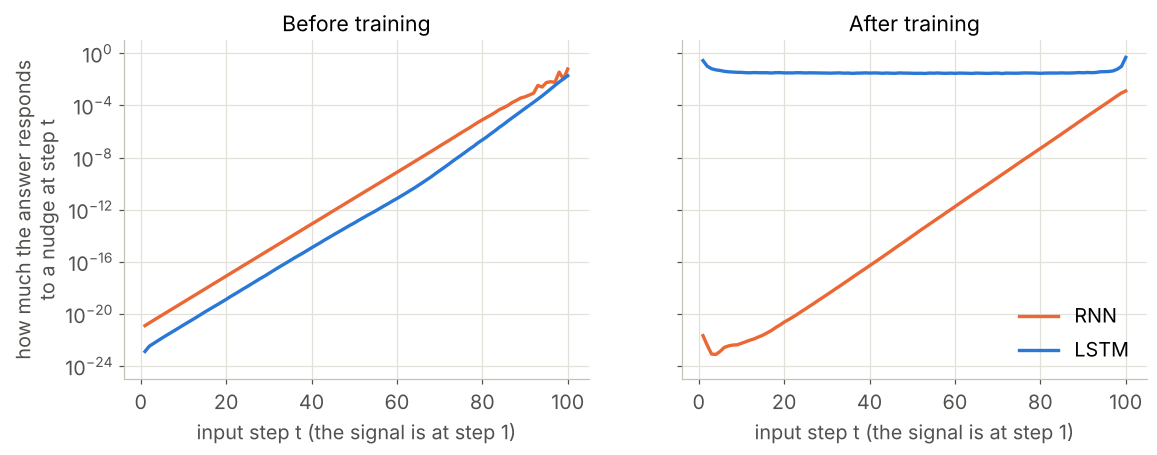

In [9]:
def input_sensitivity(model, x):
    x = x.clone().requires_grad_(True)
    grad, = torch.autograd.grad(model(x).sum(), x)
    return grad.norm(dim=-1).mean(0).numpy()      # one number per step


def fresh(cell, seed=0):
    torch.manual_seed(seed)
    return MemoryNet(cell).eval()


def trained(cell):
    model = MemoryNet(cell)
    model.load_state_dict(torch.load(SAVED / f"l16_{cell}_L100_seed0.pt"))
    return model.eval()


x_first, _, _ = memory_batch(256, 100, torch.Generator().manual_seed(7), pos=torch.zeros(256, dtype=torch.long))
sens = {(tag, cell): input_sensitivity(get(cell), x_first)
        for tag, get in [("init", fresh), ("trained", trained)] for cell in ["rnn", "lstm", "gru"]}
for (tag, cell), s in sens.items():
    print(f"{tag:8s} {NAMES[cell]:4s}  step 1: {s[0]:.1e}   step 50: {s[49]:.1e}   step 100: {s[99]:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True)
steps = np.arange(1, 101)
for ax, tag, title in [(axes[0], "init", "Before training"), (axes[1], "trained", "After training")]:
    for cell in ["rnn", "lstm"]:
        ax.plot(steps, sens[(tag, cell)], color=COLOURS[cell], lw=2.2, label=NAMES[cell])
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("input step t (the signal is at step 1)")
    ax.set_ylim(1e-25, 10)
axes[0].set_ylabel("how much the answer responds\nto a nudge at step t")
axes[1].legend(loc="lower right")
fig.savefig(FIGS / "l16_gradient_per_step.png")
plt.show()

# the same two panels as separate images, for the slides
for tag, title in [("init", "before"), ("trained", "after")]:
    f1, a1 = plt.subplots(figsize=(7.5, 4.0))
    for cell in ["rnn", "lstm"]:
        a1.plot(steps, sens[(tag, cell)], color=COLOURS[cell], lw=2.4, label=NAMES[cell])
    a1.set_yscale("log")
    a1.set_ylim(1e-25, 10)
    a1.set_xlabel("input step t (the signal is at step 1)")
    a1.set_ylabel("how much the answer responds\nto a nudge at step t")
    a1.legend(loc="lower right")
    f1.savefig(FIGS / f"l16_gradient_{title}.png")
    plt.close(f1)

Before training, **all** the networks pass almost nothing back from step 100 to step 1: the gates do not remove vanishing gradients by themselves. Training changes that for the LSTM, which learns to keep its forget gates open, starting from the sequences where the signal sits close to the end. The plain RNN has no such knob, and stays deaf to the start of the sequence.

## 5. Exploding gradients and clipping

If the factors are larger than 1, the product explodes instead. Here we scale an untrained RNN's recurrent weights by 4, so its factors exceed 1, and look at the gradient before and after `clip_grad_norm_`.

In [10]:
torch.manual_seed(0)
loud = MemoryNet("rnn")
with torch.no_grad():
    loud.rnn.weight_hh_l0.mul_(4.0)        # recurrent weights four times larger
xb, yb, _ = memory_batch(64, 100, torch.Generator().manual_seed(1))
loss = nn.BCEWithLogitsLoss()(loud(xb), yb)
loss.backward()
before = nn.utils.clip_grad_norm_(loud.parameters(), max_norm=1.0)   # returns the norm before clipping
after = torch.sqrt(sum((p.grad ** 2).sum() for p in loud.parameters()))
print(f"gradient norm before clipping: {before:.1f}")
print(f"gradient norm after clipping:  {after:.2f}")
print("Clipping rescales the whole gradient vector, keeping its direction. It cannot enlarge a vanishing one.")

gradient norm before clipping: 12639754.0
gradient norm after clipping:  1.00
Clipping rescales the whole gradient vector, keeping its direction. It cannot enlarge a vanishing one.


## 6. Inside an LSTM

### 6a. An LSTM unit built by hand

One LSTM unit with **20 weights set by hand** (like AND, OR and XNOR on 18 Jan):

| gate | what we want | weights on (value, marker) | bias |
|---|---|---|---|
| input $i$ | open only at the marker | (0, 20) | −10 |
| forget $f$ | always keep | (0, 0) | +10 |
| candidate $g$ | the value itself | (2, 0) | 0 |
| output $o$ | always show | (0, 0) | +10 |

All recurrent weights are 0. PyTorch orders the four gates as $i, f, g, o$.

In [11]:
def hand_built_lstm():
    lstm = nn.LSTM(input_size=2, hidden_size=1, batch_first=True)
    head = nn.Linear(1, 1)
    with torch.no_grad():
        # rows: input gate i, forget gate f, candidate g, output gate o; columns: value, marker
        lstm.weight_ih_l0.copy_(torch.tensor([[0., 20.], [0., 0.], [2., 0.], [0., 0.]]))
        lstm.bias_ih_l0.copy_(torch.tensor([-10., 10., 0., 10.]))
        lstm.weight_hh_l0.zero_()
        lstm.bias_hh_l0.zero_()
        head.weight.fill_(10.0)
        head.bias.zero_()
    return lstm, head


lstm1, head1 = hand_built_lstm()
print("weights:", sum(p.numel() for p in lstm1.parameters()), "in the LSTM, 2 in the read-out")
for L in [100, 1000]:
    xb, yb, _ = memory_batch(2000, L, torch.Generator().manual_seed(3))
    with torch.no_grad():
        out, _ = lstm1(xb)
        acc = ((head1(out[:, -1]).squeeze(-1) > 0).float() == yb).float().mean().item()
    print(f"{L:5d} steps: accuracy {acc:.1%}")

weights: 20 in the LSTM, 2 in the read-out
  100 steps: accuracy 100.0%
 1000 steps: accuracy 100.0%


matches nn.LSTM: True


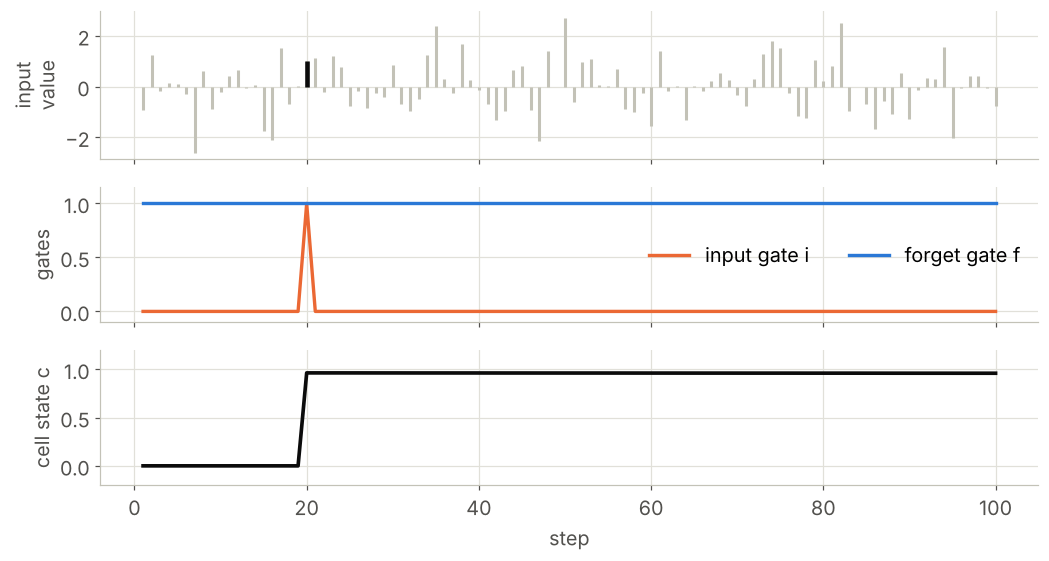

cell state: -0.000 at step 19, 0.964 at step 20, 0.960 at step 100


In [12]:
def unroll_lstm(lstm, x):
    # The LSTM equations, one step at a time, recording every gate
    W_x, W_h = lstm.weight_ih_l0, lstm.weight_hh_l0
    b = lstm.bias_ih_l0 + lstm.bias_hh_l0
    H = W_h.shape[1]
    h, c = torch.zeros(x.shape[0], H), torch.zeros(x.shape[0], H)
    record = {k: [] for k in "ifgoch"}
    for t in range(x.shape[1]):
        i, f, g, o = (x[:, t] @ W_x.T + h @ W_h.T + b).split(H, dim=1)
        i, f, g, o = torch.sigmoid(i), torch.sigmoid(f), torch.tanh(g), torch.sigmoid(o)
        c = f * c + i * g                  # the memory lane: keep part, add part
        h = o * torch.tanh(c)              # what the unit shows
        for k, v in zip("ifgoch", (i, f, g, o, c, h)):
            record[k].append(v)
    return {k: torch.stack(v, 1) for k, v in record.items()}


with torch.no_grad():
    rec = unroll_lstm(lstm1, x_example)    # the example from section 1: signal +1 at step 20
    out, _ = lstm1(x_example)
print("matches nn.LSTM:", torch.allclose(rec["h"], out, atol=1e-6))

fig, axes = plt.subplots(3, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.1, 1, 1]})
steps = np.arange(1, 101)
axes[0].vlines(steps, 0, x_example[0, :, 0], color="#c3c2b7", lw=2)
axes[0].vlines(20, 0, x_example[0, 19, 0], color=INK, lw=3)
axes[0].set_ylabel("input\nvalue")
axes[1].plot(steps, rec["i"][0, :, 0], color="#eb6834", lw=2.2, label="input gate i")
axes[1].plot(steps, rec["f"][0, :, 0], color="#2a78d6", lw=2.2, label="forget gate f")
axes[1].set_ylim(-0.1, 1.15)
axes[1].set_ylabel("gates")
axes[1].legend(loc="center right", ncol=2)
axes[2].plot(steps, rec["c"][0, :, 0], color=INK, lw=2.4)
axes[2].set_ylim(-0.2, 1.2)
axes[2].set_ylabel("cell state c")
axes[2].set_xlabel("step")
fig.savefig(FIGS / "l16_handbuilt_unit.png")
plt.show()
print(f"cell state: {rec['c'][0, 18, 0]:.3f} at step 19, {rec['c'][0, 19, 0]:.3f} at step 20, {rec['c'][0, 99, 0]:.3f} at step 100")

### 6b. What training found

The trained networks are not this tidy, but the effect is the same. We feed each trained 100-step network the same noise twice, once with signal +1 and once with −1 (at step 11), and measure how different its two hidden states are at every later step. If the difference dies, the information is gone.

 0 steps after the signal:  RNN 4.2e-01   LSTM 2.93
 5 steps after the signal:  RNN 9.7e-02   LSTM 5.92
10 steps after the signal:  RNN 1.4e-02   LSTM 6.21
20 steps after the signal:  RNN 1.2e-04   LSTM 6.26
40 steps after the signal:  RNN 6.7e-09   LSTM 6.26
89 steps after the signal:  RNN 0.0e+00   LSTM 6.27


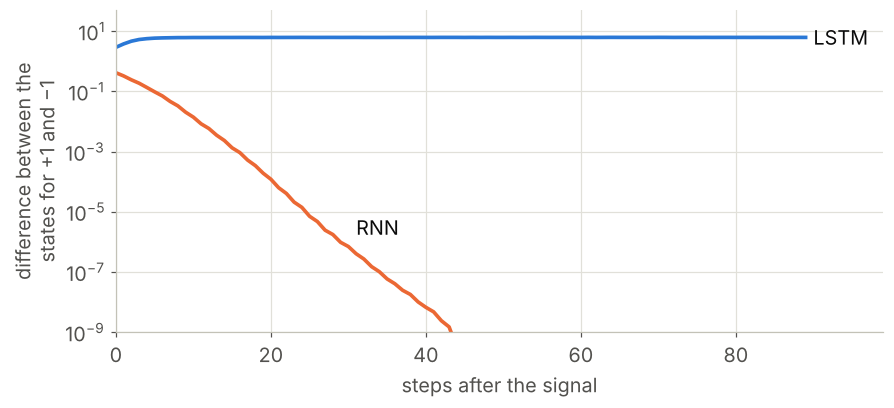

In [13]:
def unroll_rnn(rnn, x):
    W_x, W_h = rnn.weight_ih_l0, rnn.weight_hh_l0
    b = rnn.bias_ih_l0 + rnn.bias_hh_l0
    h, states = torch.zeros(x.shape[0], W_h.shape[0]), []
    for t in range(x.shape[1]):
        h = torch.tanh(x[:, t] @ W_x.T + h @ W_h.T + b)
        states.append(h)
    return torch.stack(states, 1)


P, B = 10, 200
x_plus, _, _ = memory_batch(B, 100, torch.Generator().manual_seed(11), pos=torch.full((B,), P), signal=torch.ones(B))
x_minus = x_plus.clone()
x_minus[:, P, 0] = -1.0                       # same noise, opposite signal

with torch.no_grad():
    rnn_t, lstm_t = trained("rnn"), trained("lstm")
    gap_rnn = (unroll_rnn(rnn_t.rnn, x_plus) - unroll_rnn(rnn_t.rnn, x_minus)).norm(dim=-1).mean(0).numpy()
    gap_lstm = (unroll_lstm(lstm_t.rnn, x_plus)["h"] - unroll_lstm(lstm_t.rnn, x_minus)["h"]).norm(dim=-1).mean(0).numpy()

for k in [0, 5, 10, 20, 40, 89]:
    print(f"{k:2d} steps after the signal:  RNN {gap_rnn[P + k]:.1e}   LSTM {gap_lstm[P + k]:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
after = np.arange(0, 100 - P)
ax.plot(after, gap_rnn[P:], color=COLOURS["rnn"], lw=2.4)
ax.plot(after, gap_lstm[P:], color=COLOURS["lstm"], lw=2.4)
ax.text(after[-1] + 1, gap_lstm[-1], "LSTM", va="center", color=INK)
ax.text(31, 3e-6, "RNN", va="center", color=INK)
ax.set_yscale("log")
ax.set_ylim(1e-9, 50)
ax.set_xlim(0, 99)
ax.set_xlabel("steps after the signal")
ax.set_ylabel("difference between the\nstates for +1 and −1")
fig.savefig(FIGS / "l16_memory_trace.png")
plt.show()

**How the trained LSTM holds the bit.** Training found a messier solution than our hand-built unit. The units below end near +1 after one signal and near −1 after the other: the bit is held in their outputs and refreshed at every step through the recurrent weights, while their forget gates stay fairly open. The details differ from the hand-built unit; the effect is the same, since the information survives 90 steps of noise.

In [14]:
with torch.no_grad():
    rp, rm = unroll_lstm(lstm_t.rnn, x_plus), unroll_lstm(lstm_t.rnn, x_minus)
gap_end = (rp["h"][:, -1] - rm["h"][:, -1]).abs().mean(0)
print(" unit   forget gate after +1   after −1    output at the end: +1    −1")
for k in torch.argsort(gap_end, descending=True)[:6].tolist():
    print(f"{k:5d}   {rp['f'][:, P + 1:, k].mean():19.2f}   {rm['f'][:, P + 1:, k].mean():8.2f}"
          f"   {rp['h'][:, -1, k].mean():20.2f}   {rm['h'][:, -1, k].mean():5.2f}")

 unit   forget gate after +1   after −1    output at the end: +1    −1
    4                  0.61       0.82                   0.92   -0.98
   15                  0.80       0.69                   0.95   -0.95
    3                  0.85       0.93                   0.95   -0.95
   21                  0.90       0.77                   0.99   -0.83
   25                  0.83       0.72                   0.98   -0.82
   13                  0.20       0.94                   0.52   -0.98


## 7. The GRU

The GRU (Cho et al., 2014) merges the cell and the hidden state and uses two gates, update $z$ and reset $r$:

$$\tilde h_t = \tanh\big(W_x x_t + r_t \odot (W_h h_{t-1}) + b\big), \qquad h_t = z_t \odot h_{t-1} + (1 - z_t) \odot \tilde h_t$$

When $z_t \approx 1$ the old state passes through unchanged, just like a forget gate near 1. It has three weight blocks where the LSTM has four.

In [15]:
for cell in ["rnn", "gru", "lstm"]:
    n = sum(p.numel() for p in MemoryNet(cell).rnn.parameters())
    accs = [r["accuracy"] for r in grid if r["cell"] == cell and r["L"] == 100]
    print(f"{NAMES[cell]:4s} recurrent layer: {n:5,d} parameters · 100-step accuracy {np.mean(accs):.0%}")

RNN  recurrent layer: 1,152 parameters · 100-step accuracy 50%
GRU  recurrent layer: 3,456 parameters · 100-step accuracy 100%
LSTM recurrent layer: 4,608 parameters · 100-step accuracy 100%


## 8. Back to Charlottetown

Friday's forecasting task, data and split, with the recurrent layer swapped: `layer=nn.LSTM` or `layer=nn.GRU`. Nothing else changes.

In [16]:
SEED, WINDOW, HIDDEN = 4140, 14, 32
temp = pd.read_csv(DATA / "charlottetown_daily_2013_2025.csv", parse_dates=["date"], index_col="date")["mean_temp"].interpolate()
values, dates = temp.values.astype(np.float32), temp.index
TRAIN_END, VAL_END = pd.Timestamp("2022-01-01"), pd.Timestamp("2024-01-01")
MU, SD = values[dates < TRAIN_END].mean(), values[dates < TRAIN_END].std()
z = (values - MU) / SD
X = np.stack([z[t - WINDOW:t] for t in range(WINDOW, len(z))])
y = z[WINDOW:]
target_dates = dates[WINDOW:]
idx_train = np.where(target_dates < TRAIN_END)[0]
idx_val = np.where((target_dates >= TRAIN_END) & (target_dates < VAL_END))[0]
idx_test = np.where(target_dates >= VAL_END)[0]
Xt, yt = torch.tensor(X), torch.tensor(y)


def mae_celsius(pred_z, true_z):
    return float(np.mean(np.abs(pred_z - true_z)) * SD)


class RNNForecaster(nn.Module):        # the same class as on Friday
    def __init__(self, hidden=HIDDEN, layer=nn.RNN):
        super().__init__()
        self.rnn = layer(input_size=1, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x.unsqueeze(-1))
        return self.head(out[:, -1]).squeeze(-1)


def fit(model, epochs=40, lr=1e-3, batch_size=64, seed=SEED):   # the same loop as on Friday
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best_mae, best_state = float("inf"), None
    for epoch in range(epochs):
        model.train()
        order = idx_train[torch.randperm(len(idx_train), generator=gen).numpy()]
        for i in range(0, len(order), batch_size):
            b = order[i:i + batch_size]
            opt.zero_grad()
            loss_fn(model(Xt[b]), yt[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val_mae = mae_celsius(model(Xt[idx_val]).numpy(), y[idx_val])
        if val_mae < best_mae:
            best_mae, best_state = val_mae, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model


forecast = {}
for name, layer in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    torch.manual_seed(SEED)
    model = RNNForecaster(layer=layer)
    path = SAVED / ("l15_rnn.pt" if name == "RNN" else f"l16_forecast_{name.lower()}.pt")
    if TRAIN_FORECAST and name != "RNN":
        fit(model)
        torch.save(model.state_dict(), path)
    else:
        model.load_state_dict(torch.load(path))
    with torch.no_grad():
        forecast[name] = (mae_celsius(model(Xt[idx_test]).numpy(), y[idx_test]), sum(p.numel() for p in model.parameters()))

persistence = mae_celsius(X[idx_test, -1], y[idx_test])
print(f"{'model':12s}{'test MAE (°C)':>14s}{'parameters':>12s}")
print(f"{'Persistence':12s}{persistence:14.2f}{'—':>12s}")
for name, (mae, n) in forecast.items():
    print(f"{name:12s}{mae:14.2f}{n:12,d}")

model        test MAE (°C)  parameters
Persistence           2.48           —
RNN                   2.29       1,153
LSTM                  2.27       4,513
GRU                   2.27       3,393


The gates barely matter here: the useful past for tomorrow's temperature is a few days long. Choose the model by the length of the dependencies you need, and measure against a baseline.

## 9. Exercises

1. **The signal always first.** Put the signal at step 1 of every sequence (`pos=torch.zeros(...)` in `memory_batch`) and train the LSTM on 100 steps. Then set the forget-gate bias to 1 before training (`model.rnn.bias_ih_l0[32:64].fill_(1.0)`) and try again. What changes, and why?
2. **Noise.** Train the RNN on 100 steps with `noise_sd=0.1`. What does this tell you about *why* the RNN failed?
3. **Width.** Give the RNN 128 units. Does memory improve?
4. **Your own hand-built unit.** Change the hand-built LSTM so that it reports the *last* marked value when two signals appear.
5. **Bidirectional.** `nn.LSTM(..., bidirectional=True)` reads the sequence both ways. Why is that allowed for the memory test but not for Friday's forecast?